#  Final Evaluation on the Held-Out Test Set

## Objective
Estimate out-of-sample performance of the three tuned models on the 20% test set (n = 312) that was locked before any exploratory analysis or tuning.

## Pre-specified analysis plan
- Models are refitted on the full training set (n = 1,246) with the settings selected by training-set CV.
- Each model predicts the test set once.
- Two operating points: the default 0.5 threshold, and 0.32, fixed from training out-of-fold predictions (highest threshold with recall ≥ 0.80).
- No setting, feature or threshold is changed after viewing test results.
- Results are unweighted, cross-sectional associations. This is not a validated diagnostic tool.

> **Post-hoc re-evaluation.** The original test-set evaluation (logistic regression ROC-AUC 0.742, random forest 0.737, XGBoost 0.729) used a preprocessor that wrongly standardised missing-indicator columns. This run uses the corrected preprocessor with identical settings and the same pre-specified threshold (0.32). It was performed after the original test results were seen, so both versions are reported and neither was chosen on the basis of test performance.

##  Load data and refit tuned models on the full training set

**Purpose:** Produce final fitted models using the settings chosen by training-set CV.
**Method:** Pipelines with the preprocessor inside, fitted on `train.csv` only.
**Risk:** Any change to settings after seeing test scores would invalidate the test estimate.

In [4]:
import sys
sys.path.append("..")
import warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from src.preprocessing import build_preprocessor, NUMERIC, BINARY, CATEGORICAL, TARGET

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")
FEATS = NUMERIC + BINARY + CATEGORICAL
Xtr, ytr = train[FEATS], train[TARGET].astype(int)
Xte, yte = test[FEATS], test[TARGET].astype(int)
print(Xtr.shape, Xte.shape, "| test positive rate:", round(yte.mean(), 3))

specs = {
    "logreg": (LogisticRegression(max_iter=2000, C=1), True),
    "random_forest": (RandomForestClassifier(n_estimators=300, max_depth=4,
                      min_samples_leaf=5, random_state=42, n_jobs=-1), False),
    "xgboost": (XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.03,
                min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                eval_metric="logloss", random_state=42), False),
}
fitted = {}
for name, (m, scale) in specs.items():
    fitted[name] = Pipeline([("pre", build_preprocessor(scale=scale)),
                             ("model", m)]).fit(Xtr, ytr)
print("fitted:", list(fitted))

(1246, 9) (312, 9) | test positive rate: 0.426
fitted: ['logreg', 'random_forest', 'xgboost']


##  Test-set metrics at two pre-specified thresholds

**Purpose:** Report discrimination (ROC-AUC) and classification metrics at 0.5 and at the pre-specified 0.32.
**Method:** One prediction per model on the test set. Specificity and missed cases are reported alongside recall, because missed cases are the priority.

In [5]:
from sklearn.metrics import (roc_auc_score, recall_score, precision_score,
                             f1_score, confusion_matrix)

rows, probs = [], {}
for name, pipe in fitted.items():
    p = pipe.predict_proba(Xte)[:, 1]
    probs[name] = p
    for t in [0.5, 0.32]:
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
        rows.append({"model": name, "threshold": t,
                     "roc_auc": round(roc_auc_score(yte, p), 3),
                     "recall": round(recall_score(yte, pred), 3),
                     "precision": round(precision_score(yte, pred), 3),
                     "f1": round(f1_score(yte, pred), 3),
                     "specificity": round(tn / (tn + fp), 3),
                     "missed": fn, "false_pos": fp})
print(pd.DataFrame(rows).to_string(index=False))

        model  threshold  roc_auc  recall  precision    f1  specificity  missed  false_pos
       logreg       0.50    0.744   0.586      0.690 0.634        0.804      55         35
       logreg       0.32    0.744   0.872      0.520 0.652        0.402      17        107
random_forest       0.50    0.737   0.466      0.674 0.551        0.832      71         30
random_forest       0.32    0.737   0.902      0.472 0.620        0.251      13        134
      xgboost       0.50    0.729   0.511      0.618 0.560        0.765      65         42
      xgboost       0.32    0.729   0.850      0.521 0.646        0.419      20        104


### Interpretation (post-hoc, corrected preprocessing)
| Model | Threshold | ROC-AUC | Recall | Precision | Specificity | Missed | False positives |
|---|---|---|---|---|---|---|---|
| Logistic regression | 0.50 | 0.744 | 0.586 | 0.690 | 0.804 | 55 | 35 |
| Logistic regression | 0.32 | 0.744 | 0.872 | 0.520 | 0.402 | 17 | 107 |
| Random forest | 0.50 | 0.737 | 0.466 | 0.674 | 0.832 | 71 | 30 |
| Random forest | 0.32 | 0.737 | 0.902 | 0.472 | 0.251 | 13 | 134 |
| XGBoost | 0.50 | 0.729 | 0.511 | 0.618 | 0.765 | 65 | 42 |
| XGBoost | 0.32 | 0.729 | 0.850 | 0.521 | 0.419 | 20 | 104 |

With corrected preprocessing, test ROC-AUC was 0.744 (logistic regression), 0.737 (random forest) and 0.729 (XGBoost). The tree models are identical to the original evaluation, as expected, because tree splits are unaffected by feature scaling. Logistic regression changed marginally (AUC 0.742 to 0.744; at the 0.32 threshold, 3 additional false positives and unchanged recall of 0.872). These differences are well inside the sampling uncertainty of a 312-participant test set (about ±0.03 for AUC). The conclusions are unchanged: the models cannot be ranked, high recall requires flagging most participants without a marker, and the model is not a practical triage tool. This evaluation was run after the original test results were seen, so it is reported as post-hoc alongside the original.

## Confusion matrices and ROC curves

**Purpose:** Show where each model errs and compare discrimination visually.
**Method:** Confusion matrices at the pre-specified 0.32 threshold; overlaid test ROC curves.

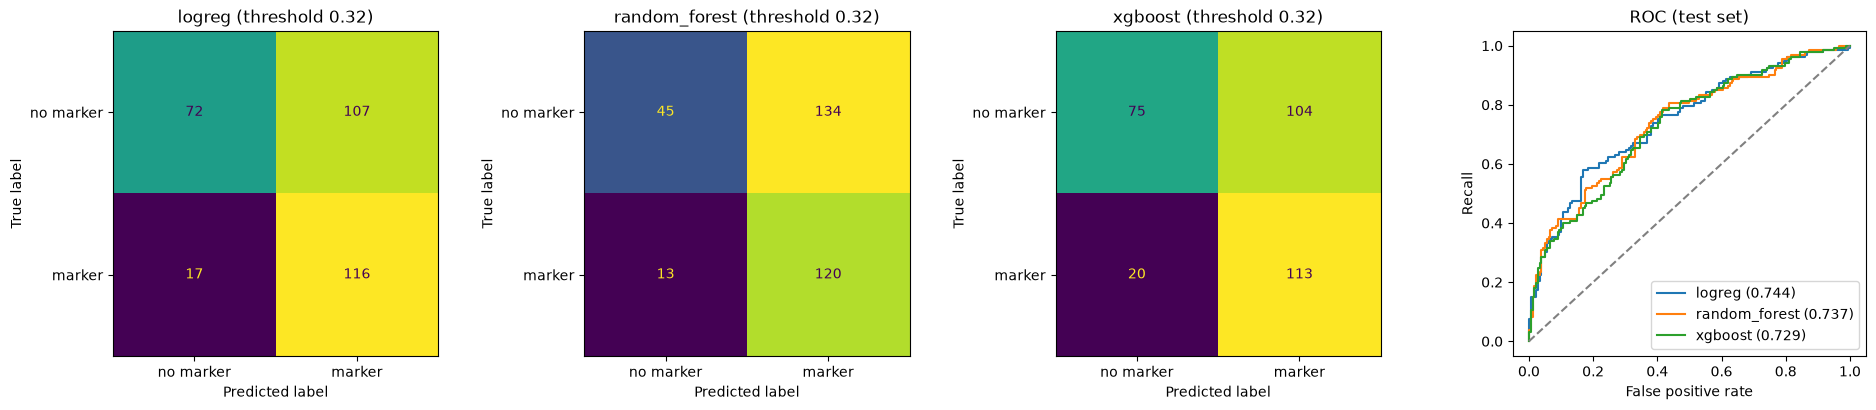

In [6]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
for a, (name, p) in zip(ax[:3], probs.items()):
    ConfusionMatrixDisplay.from_predictions(yte, (p >= 0.32).astype(int), ax=a,
                                            colorbar=False, display_labels=["no marker", "marker"])
    a.set_title(f"{name} (threshold 0.32)")
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p)
    ax[3].plot(fpr, tpr, label=f"{name} ({roc_auc_score(yte, p):.3f})")
ax[3].plot([0, 1], [0, 1], "--", color="grey")
ax[3].set(xlabel="False positive rate", ylabel="Recall", title="ROC (test set)")
ax[3].legend()
plt.tight_layout()
plt.savefig("../reports/figures/test_confusion_roc.png", dpi=150)
plt.show()

### Interpretation
| Model | Threshold | ROC-AUC | Recall | Precision | Specificity | Missed | False positives |
|---|---|---|---|---|---|---|---|
| Logistic regression | 0.50 | 0.742 | 0.579 | 0.688 | 0.804 | 56 | 35 |
| Logistic regression | 0.32 | 0.742 | 0.872 | 0.527 | 0.419 | 17 | 104 |
| Random forest | 0.50 | 0.737 | 0.466 | 0.674 | 0.832 | 71 | 30 |
| Random forest | 0.32 | 0.737 | 0.902 | 0.472 | 0.251 | 13 | 134 |
| XGBoost | 0.50 | 0.729 | 0.511 | 0.618 | 0.765 | 65 | 42 |
| XGBoost | 0.32 | 0.729 | 0.850 | 0.521 | 0.419 | 20 | 104 |

On the held-out test set (n = 312; 133 with a kidney marker), ROC-AUC was 0.742 for logistic regression, 0.737 for random forest and 0.729 for XGBoost, consistent with the training cross-validation estimates (0.70 to 0.73). With a test set of this size, the sampling uncertainty of an AUC is roughly ±0.03, so the models cannot be ranked; the regularised logistic regression, pre-specified as primary, performs at least as well as the flexible models. At the pre-specified threshold of 0.32, logistic regression detected 116 of 133 participants with a marker (recall 0.872) and missed 17, but flagged 104 of 179 participants without a marker (specificity 0.419, precision 0.527). Random forest reached higher recall (0.902) only by flagging most participants (specificity 0.251). Precision of about 0.52 against a prevalence of 0.426 is modest enrichment, so high-recall operation approximates testing most participants. The model separates risk moderately and is not a validated diagnostic or triage tool; the exercise is a methodological demonstration. The test set was used once, and no setting was changed afterwards. Results are unweighted associations in a cross-sectional sample.

> **Post-hoc re-evaluation.** The original test-set evaluation (logistic regression ROC-AUC 0.742, random forest 0.737, XGBoost 0.729) used a preprocessor that wrongly standardised missing-indicator columns. This run uses the corrected preprocessor with identical settings and the same pre-specified threshold (0.32). It was performed after the original test results were seen, so both versions are reported and neither was chosen on the basis of test performance.